In [1]:
import numpy as np
import cv2 as cv2
import matplotlib.pyplot as plt

In [2]:
img = cv2.imread("anhTest.jpg", cv2.IMREAD_GRAYSCALE)

## Một số hàm dùng hỗ trợ

In [3]:
def display(title, img):
    cv2.imshow(title, img)
    cv2.waitKey(0)
    cv2.destroyAllWindows()

In [4]:
def DrawHistogram(img):
    hist, bin_edges = np.histogram(img.flatten(), bins=256, range=[0, 256])

    plt.figure(figsize=(10, 4))
    plt.title("Biểu đồ Histogram")
    plt.xlabel("Mức xám (Intensity)")
    plt.ylabel("Số lượng pixel: ")

    # Dùng bin_edges[:-1] làm tọa độ x, chiều rộng cột là 1
    plt.bar(bin_edges[:-1], hist, width=1.0)

    plt.xlim([0, 256])
    plt.show()

## Xây dựng bảng tra duy nhất cho toàn ảnh

In [5]:
N = img.shape[0] * img.shape[1]
L = 256

# Lưu ý: np.histogram mặc định chỉ có 10 bin, phải ép 256 bin
hist, bins = np.histogram(img, bins=256, range=(0, 256))

c = np.cumsum(hist) / N          # CDF chuẩn hóa về [0, 1]
T = np.round((L - 1) * c)        # bảng tra T(k)

print("Bảng tra T có giá trị như sau")
print(T)

Bảng tra T có giá trị như sau
[  2.  13.  32.  83. 108. 132. 152. 163. 170. 178. 184. 189. 193. 197.
 200. 203. 205. 208. 210. 212. 214. 216. 219. 221. 223. 224. 226. 227.
 229. 230. 231. 232. 233. 233. 234. 235. 235. 236. 236. 237. 237. 238.
 238. 238. 239. 239. 239. 240. 240. 241. 241. 241. 242. 242. 242. 242.
 243. 243. 243. 244. 244. 244. 245. 245. 245. 245. 246. 246. 246. 247.
 247. 247. 247. 247. 248. 248. 248. 248. 248. 248. 248. 249. 249. 249.
 249. 249. 249. 249. 249. 249. 249. 250. 250. 250. 250. 250. 250. 250.
 250. 250. 250. 250. 250. 250. 251. 251. 251. 251. 251. 251. 251. 251.
 251. 251. 251. 251. 251. 251. 251. 251. 251. 252. 252. 252. 252. 252.
 252. 252. 252. 252. 252. 252. 252. 252. 252. 252. 252. 252. 252. 252.
 252. 252. 252. 252. 253. 253. 253. 253. 253. 253. 253. 253. 253. 253.
 253. 253. 253. 253. 253. 253. 253. 253. 253. 253. 253. 253. 253. 253.
 253. 253. 253. 253. 253. 253. 253. 253. 253. 253. 253. 253. 253. 253.
 253. 254. 254. 254. 254. 254. 254. 254. 254. 2

In [6]:
# Tính toán CDF (Đạo hàm của bảng tra)
CDF =  np.zeros(len(hist))

for k in range(0, len(hist)):
    CDF[k] = (L - 1) * (hist[k] / N)

print(CDF)
print("Ta nhận thấy có độc dốc rất lớn")

[2.04566667e+00 1.14296667e+01 1.81390000e+01 5.13825000e+01
 2.52846667e+01 2.37433333e+01 2.03886667e+01 1.06590000e+01
 7.15700000e+00 7.43750000e+00 6.60166667e+00 4.99516667e+00
 4.11116667e+00 3.79666667e+00 3.07700000e+00 2.58966667e+00
 2.42250000e+00 2.39700000e+00 2.22416667e+00 2.21283333e+00
 2.26383333e+00 2.13350000e+00 2.30916667e+00 2.00600000e+00
 1.86150000e+00 1.64616667e+00 1.68300000e+00 1.50166667e+00
 1.32600000e+00 1.25800000e+00 9.06666667e-01 8.47166667e-01
 7.96166667e-01 6.82833333e-01 6.99833333e-01 6.09166667e-01
 5.61000000e-01 5.41166667e-01 4.84500000e-01 4.81666667e-01
 4.36333333e-01 4.53333333e-01 4.10833333e-01 3.42833333e-01
 4.16500000e-01 3.76833333e-01 3.11666667e-01 3.51333333e-01
 3.51333333e-01 4.08000000e-01 3.14500000e-01 3.42833333e-01
 3.37166667e-01 3.23000000e-01 3.37166667e-01 2.89000000e-01
 3.06000000e-01 3.08833333e-01 3.11666667e-01 3.03166667e-01
 2.74833333e-01 2.91833333e-01 2.83333333e-01 2.77666667e-01
 2.83333333e-01 2.606666

## Xây dựng hàm

In [7]:
ALPHA = 120   # tham số trong công thức ngưỡng cắt B


def clip_histogram(hist, clip_limit):
    """Cắt và phân phối lại lược đồ.
    hist: mảng (L,) số nguyên. Trả về mảng (L,) đã cắt, tổng không đổi."""

    # Làm việc trên bản sao kiểu int64, không sửa mảng đầu vào
    hist = np.array(hist, dtype=np.int64)
    n = hist.size                      # số mức xám L
    N = int(hist.sum())                # tổng số pixel của CHÍNH lược đồ này (không dùng N toàn cục)

    # Ngưỡng cắt B (lấy phần nguyên, tối thiểu 1)
    B = (N / n) * (1 + (ALPHA / 100) * (clip_limit - 1))
    B = max(1, int(B))

    # Cắt và cộng tổng phần dư E
    e_k = np.maximum(hist - B, 0)
    E = int(e_k.sum())
    out = np.minimum(hist, B)

    # Phân phối E đều cho toàn bộ L bin
    out += E // n

    # Phần lẻ còn lại: rải 1 đơn vị vào các bin cách đều
    rem = E - (E // n) * n
    if rem > 0:
        step = max(n // rem, 1)
        idx = (np.arange(rem) * step) % n
        out[idx] += 1

    return out

In [8]:
# Test trên một ô 64x64 (lược đồ 256 bin)
h_test = np.bincount(img[:64, :64].ravel(), minlength=256)
h_clip = clip_histogram(h_test, 2.0)

print("Tổng trước:", h_test.sum(), "| Tổng sau:", h_clip.sum())
print("Bin lớn nhất trước:", h_test.max(), "| sau:", h_clip.max())
assert h_test.sum() == h_clip.sum()

Tổng trước: 4096 | Tổng sau: 4096
Bin lớn nhất trước: 1972 | sau: 50


In [9]:
def _pad_to_grid(img, grid):
    """Padding phản xạ để H, W chia hết cho lưới."""
    gy, gx = grid
    H, W = img.shape
    ph = (-H) % gy
    pw = (-W) % gx
    if ph or pw:
        img = np.pad(img, ((0, ph), (0, pw)), mode="reflect")
    return img

In [10]:
def build_tile_luts(img, grid=(8, 8), clip_limit=2.0):
    """Trả về mảng (Gy, Gx, L) uint8: bảng tra của từng ô."""
    gy, gx = grid
    padded = _pad_to_grid(np.asarray(img, dtype=np.uint8), grid)
    th = padded.shape[0] // gy
    tw = padded.shape[1] // gx
    
    luts = np.zeros((gy, gx, L), dtype=np.uint8)
    for i in range(gy):
        for j in range(gx):
            tile = padded[i * th:(i + 1) * th, j * tw:(j + 1) * tw]
            hist = np.bincount(tile.ravel(), minlength=L)
            hist = clip_histogram(hist, clip_limit)
            cdf = np.cumsum(hist)
            lut = np.rint(cdf * (L - 1) / cdf[-1])
            luts[i, j] = np.clip(lut, 0, L - 1).astype(np.uint8)
    return luts

In [11]:
def clahe(img, grid=(8, 8), clip_limit=2.0):
    """CLAHE đầy đủ. img: (H, W) uint8. Trả về (H, W) uint8."""
    img = np.asarray(img, dtype=np.uint8)
    H, W = img.shape
    gy, gx = grid
    luts = build_tile_luts(img, grid, clip_limit)

    # Kích thước ô (theo ảnh đã padding)
    th = (H + (-H) % gy) // gy
    tw = (W + (-W) % gx) // gx

    # Toạ độ liên tục theo tâm ô: tâm ô i nằm ở (i + 0.5) * th
    fy = (np.arange(H) + 0.5) / th - 0.5
    fx = (np.arange(W) + 0.5) / tw - 0.5

    y0f = np.floor(fy)
    x0f = np.floor(fx)
    wy = (fy - y0f)[:, None]
    wx = (fx - x0f)[None, :]
    y0 = np.clip(y0f, 0, gy - 1).astype(int)[:, None]
    y1 = np.clip(y0f + 1, 0, gy - 1).astype(int)[:, None]
    x0 = np.clip(x0f, 0, gx - 1).astype(int)[None, :]
    x1 = np.clip(x0f + 1, 0, gx - 1).astype(int)[None, :]

    # LUT của 4 ô lân cận, tra theo giá trị pixel
    v00 = luts[y0, x0, img].astype(np.float64)
    v01 = luts[y0, x1, img].astype(np.float64)
    v10 = luts[y1, x0, img].astype(np.float64)
    v11 = luts[y1, x1, img].astype(np.float64)

    top = v00 * (1 - wx) + v01 * wx
    bot = v10 * (1 - wx) + v11 * wx
    out = top * (1 - wy) + bot * wy
    return np.clip(np.rint(out), 0, 255).astype(np.uint8)


## Test


Độ lệch chuẩn: 26.0 -> 37.8


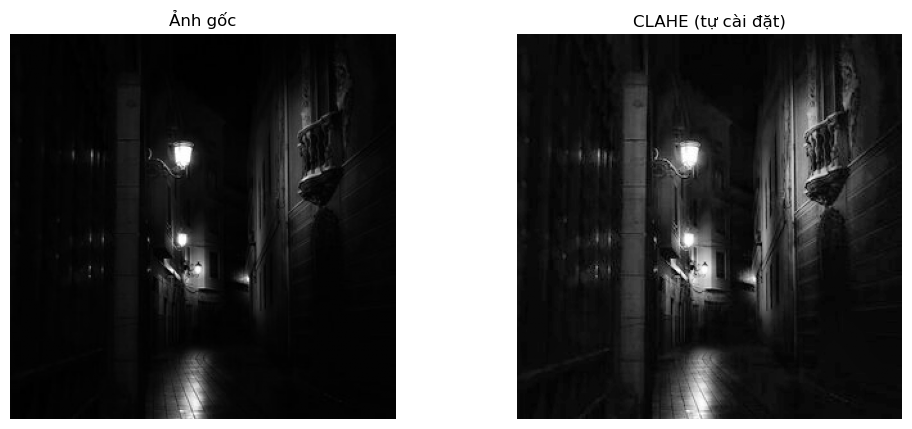

In [12]:
my_img = clahe(img, grid=(8, 8), clip_limit=2.0)

assert my_img.shape == img.shape and my_img.dtype == np.uint8
print("Độ lệch chuẩn:", img.std().round(1), "->", my_img.std().round(1))

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].imshow(img, cmap="gray", vmin=0, vmax=255); ax[0].set_title("Ảnh gốc"); ax[0].axis("off")
ax[1].imshow(my_img, cmap="gray", vmin=0, vmax=255); ax[1].set_title("CLAHE (tự cài đặt)"); ax[1].axis("off")
plt.show()

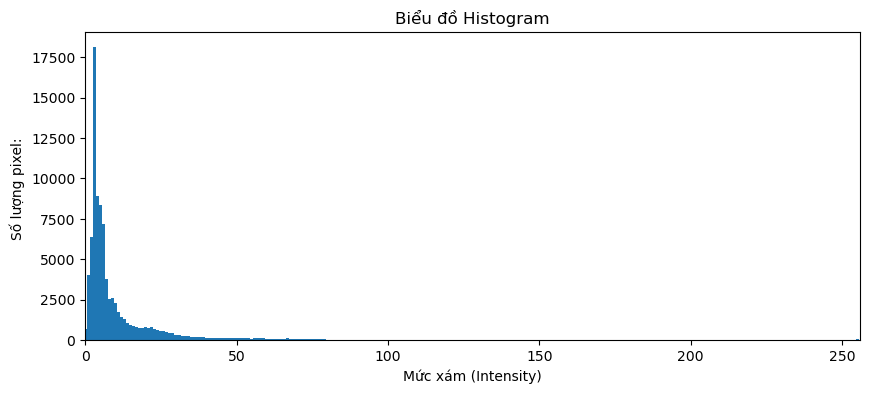

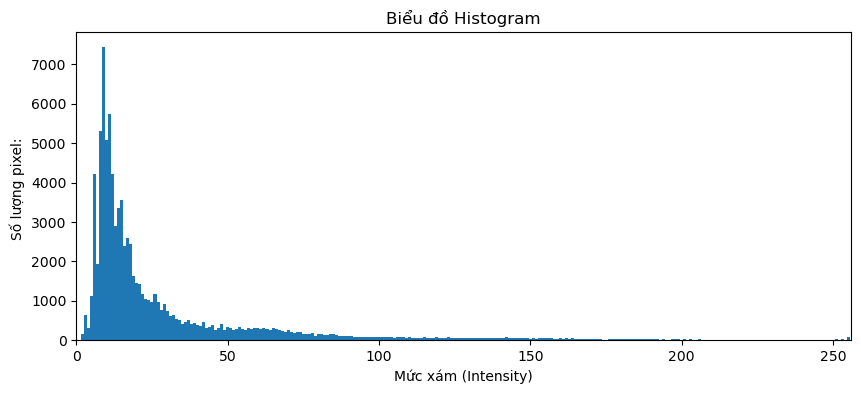

In [13]:
DrawHistogram(img)
DrawHistogram(my_img)

## Đối chiếu

In [14]:
# Đây là ô đối chiếu dùng để kiểm tra kết quả in ra của các hàm trên
# Lưu ý: đặt tên khác (clahe_cv) để KHÔNG ghi đè hàm clahe tự cài đặt

clahe_cv = cv2.createCLAHE(clipLimit=5)
clahe_img = np.clip(clahe_cv.apply(img) + 25, 0, 255).astype(np.uint8)

display("CLAHE image", clahe_img)

In [15]:
np.histogram(clahe_img)

(array([  602, 44514, 21831,  7457,  4889,  4122,  2666,  1635,  1338,
          946]),
 array([  0. ,  25.5,  51. ,  76.5, 102. , 127.5, 153. , 178.5, 204. ,
        229.5, 255. ]))

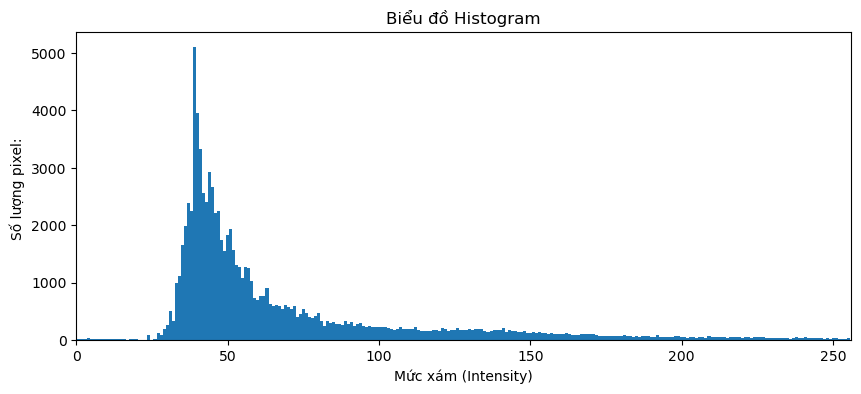

In [16]:
DrawHistogram(clahe_img)

### Đối chiếu công bằng với OpenCV

Để so sánh đúng, ta đặt `ALPHA = 100` (khi đó $B = \text{clip\_limit}\cdot N/L$, giống OpenCV), dùng cùng `clipLimit` và cùng lưới, không cộng thêm `+25`.
Hai kết quả sẽ rất gần nhau nhưng không trùng từng pixel, vì OpenCV nội suy bằng số nguyên cố định và phân phối phần dư theo cách hơi khác.

In [17]:
ALPHA = 100
try:
    mine = clahe(img, grid=(8, 8), clip_limit=2.0)
finally:
    ALPHA = 120   # luôn trả về giá trị ban đầu
ref = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(img)

diff = np.abs(mine.astype(int) - ref.astype(int))
print("Sai khác trung bình mỗi pixel:", diff.mean().round(2))
print("Sai khác lớn nhất:", diff.max())
print("Tỉ lệ pixel lệch quá 5 mức xám:", (diff > 5).mean().round(4))

Sai khác trung bình mỗi pixel: 0.07
Sai khác lớn nhất: 1
Tỉ lệ pixel lệch quá 5 mức xám: 0.0
